# Moon Dataset — Log-Likelihood Loss Experiment

Trains a `TrainableQuantumFeatureMap` on the two-moons dataset using all three loss functions:
- `pre_determine_inner`
- `hilbert_schmidt`
- `log_likelihood_macro`

Evaluates with a precomputed-kernel SVM and plots training curves.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Make sure project root is on the path when running from experiment/
ROOT = os.path.dirname(os.getcwd())
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

print("Project root:", ROOT)

Project root: d:\QuantumComputing\QuantumTrainableFeatureMapv2 - Copy


## 1. Data preparation

In [2]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

RANDOM_STATE = 42
N_TRAIN = 100
N_VAL   = 50
N_TEST  = 200

X_all, y_all = make_moons(n_samples=N_TRAIN + N_VAL + N_TEST,
                          noise=0.15, random_state=RANDOM_STATE)

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X_all, y_all, test_size=N_TEST, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=N_VAL, random_state=RANDOM_STATE)

scaler = MinMaxScaler(feature_range=(-1, 1))
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# Ensure integer labels
y_train = y_train.astype(int)
y_val   = y_val.astype(int)
y_test  = y_test.astype(int)

print(f"Train:      {X_train.shape}, classes={np.unique(y_train)}")
print(f"Validation: {X_val.shape}")
print(f"Test:       {X_test.shape}")

Train:      (100, 2), classes=[0 1]
Validation: (50, 2)
Test:       (200, 2)


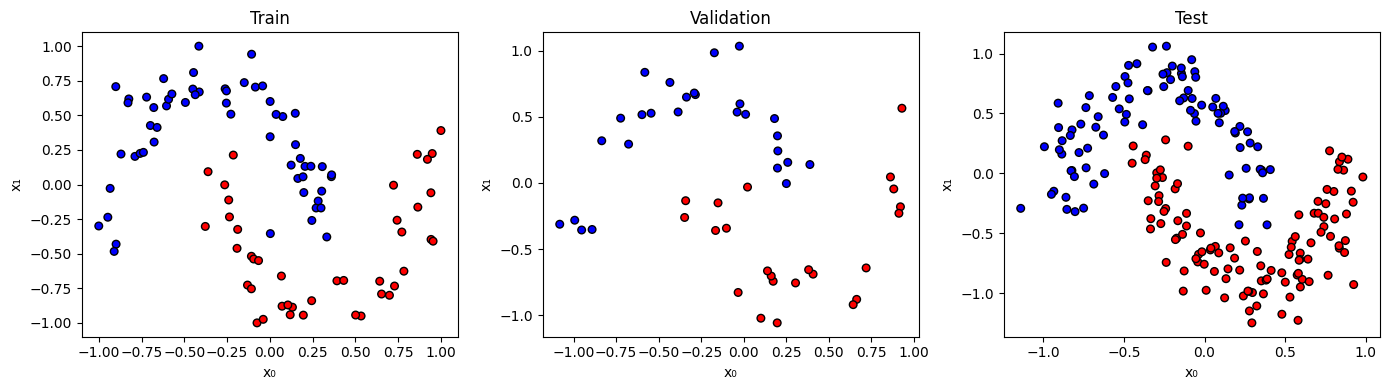

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, X, y, title in zip(axes,
                            [X_train, X_val, X_test],
                            [y_train, y_val, y_test],
                            ["Train", "Validation", "Test"]):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k", s=30)
    ax.set_title(title)
    ax.set_xlabel("x₀")
    ax.set_ylabel("x₁")
plt.tight_layout()
plt.show()

## 2. Baseline — RBF kernel SVM

In [4]:
from sklearn.metrics.pairwise import rbf_kernel
from src.classifier import ClassicalClassifier

X_train_val = np.concatenate([X_train, X_val], axis=0)
y_train_val = np.concatenate([y_train, y_val], axis=0)

K_tv   = rbf_kernel(X_train_val, X_train_val)
K_test = rbf_kernel(X_test, X_train_val)

_, rbf_test_acc, _, rbf_best_c = ClassicalClassifier.evaluate_model(
    K_tv, K_test, y_train_val, y_test)

print(f"RBF SVM  test acc = {rbf_test_acc:.4f}  best C = {rbf_best_c}")

RBF SVM  test acc = 0.9750  best C = 60.0


## 3. Quantum feature map training

Configure and train one `TrainableQuantumFeatureMap` per loss function.

In [5]:
from src.shot_simulation import create_sampler, create_noise_model
from src.feature_map import TrainableQuantumFeatureMap
from qiskit_algorithms.optimizers import SPSA

# ── experiment config ────────────────────────────────────────────────────────
DEPTH    = 1
ANSATZ   = "EfficientSU2"
MAXITER  = 200
WARMUP   = 50       # iterations before best-param tracking starts
SHOTS    = 1024

# Set noise_model=None for ideal simulation, or use create_noise_model() for noisy
# Example noisy: noise_model = create_noise_model(depol_1q=0.001, depol_2q=0.01)
NOISE_MODEL = None

LOSS_FUNCTIONS = ["pre_determine_inner", "hilbert_schmidt", "log_likelihood_macro"]

print(f"Ansatz: {ANSATZ}  depth={DEPTH}  shots={SHOTS}  maxiter={MAXITER}")
print(f"Noise model: {NOISE_MODEL}")

Ansatz: EfficientSU2  depth=1  shots=1024  maxiter=200
Noise model: None


In [6]:
# Build one shared init_theta so all loss functions start from the same point
from src.paramertrized_circuit import ParametrizedCircuit

_circ = ParametrizedCircuit.EfficientSU2_circuit(X_train.shape[1], DEPTH)
NUM_THETA = len(_circ.parameters) - X_train.shape[1]
shared_init_theta = np.random.uniform(-np.pi, np.pi, NUM_THETA)

print(f"Number of trainable parameters: {NUM_THETA}")
print(f"init_theta: {np.round(shared_init_theta, 3)}")

Total theta params for EfficientSU2: 16
Number of trainable parameters: 16
init_theta: [ 1.277 -1.995 -3.022 -2.778  1.132 -2.376 -1.777  0.191  0.757 -1.277
 -1.237  1.88  -1.495  1.854 -2.347  2.282]


In [ ]:
trained_models = {}

for loss_type in LOSS_FUNCTIONS:
    print(f"\n{'='*60}")
    print(f"Training: {loss_type}")
    print(f"{'='*60}")

    sampler = create_sampler(shots=SHOTS, noise_model=NOISE_MODEL)
    tqfm = TrainableQuantumFeatureMap(
        depth=DEPTH,
        type_ansatz=ANSATZ,
        type_loss=loss_type,
        warmup_iterations=WARMUP,
        shots=SHOTS,
        sampler=sampler,
    )
    tqfm.fit(
        X_train, y_train, X_val, y_val,
        optimizer=SPSA(maxiter=MAXITER),
        init_theta=shared_init_theta.copy(),
    )
    trained_models[loss_type] = tqfm
    print(f"Done. optimal_value={tqfm.optimal_value:.6f}  best_val_acc={tqfm.best_val_acc:.4f}")


Training: pre_determine_inner
Number of qubits: 2, Number of classes: 2
Shot-based simulation: 1024 shots
Total theta params for EfficientSU2: 16
Using loss strategy: InnerLoss


C:\Users\Nguyen Dinh Quyen\AppData\Local\Temp\ipykernel_15268\2537149932.py:8: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = create_sampler(shots=SHOTS, noise_model=NOISE_MODEL)


Class patterns: {np.int64(0): '10', np.int64(1): '01'}


## 4. Test accuracy evaluation

In [ ]:
from src.kernel_estimate import KernelMatrix
from src.classifier import ClassicalClassifier

X_train_val = np.concatenate([X_train, X_val], axis=0)
y_train_val = np.concatenate([y_train, y_val], axis=0).astype(int)

results = {}

for loss_type, tqfm in trained_models.items():
    best_p = tqfm.best_params if tqfm.best_params is not None else tqfm.optimal_params

    K_tv = KernelMatrix.compute_kernel_matrix_with_inner_products(
        X_train_val, X_train_val, best_p, tqfm.circuit,
        sampler=tqfm.sampler, shots=SHOTS)
    K_test = KernelMatrix.compute_kernel_matrix_with_inner_products(
        X_test, X_train_val, best_p, tqfm.circuit,
        sampler=tqfm.sampler, shots=SHOTS)

    _, test_acc, _, best_c = ClassicalClassifier.evaluate_model(
        K_tv, K_test, y_train_val, y_test)

    results[loss_type] = {"test_acc": test_acc, "best_c": best_c}
    print(f"{loss_type:30s}  test_acc={test_acc:.4f}  best_C={best_c}")

print(f"\nRBF baseline:                   test_acc={rbf_test_acc:.4f}  best_C={rbf_best_c}")

## 5. Training curves

In [ ]:
fig, axes = plt.subplots(1, len(LOSS_FUNCTIONS), figsize=(6 * len(LOSS_FUNCTIONS), 4))
if len(LOSS_FUNCTIONS) == 1:
    axes = [axes]

for ax, loss_type in zip(axes, LOSS_FUNCTIONS):
    tqfm = trained_models[loss_type]
    ax.plot(tqfm.loss_history, label="train loss")
    ax.set_title(loss_type)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss")
    ax.legend()

plt.suptitle("Loss history", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, len(LOSS_FUNCTIONS), figsize=(6 * len(LOSS_FUNCTIONS), 4))
if len(LOSS_FUNCTIONS) == 1:
    axes = [axes]

for ax, loss_type in zip(axes, LOSS_FUNCTIONS):
    tqfm = trained_models[loss_type]
    iters = tqfm.accuracy_iteration_indices
    if iters:
        ax.plot(iters, tqfm.train_accuracy_history, label="train acc (SVM)")
        ax.plot(iters, tqfm.val_accuracy_history,   label="val acc (SVM)")
    ax.axhline(results[loss_type]["test_acc"], color="green",
               linestyle="--", label=f"test acc={results[loss_type]['test_acc']:.3f}")
    ax.set_title(loss_type)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)

plt.suptitle("SVM accuracy during training", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
print("\n=== FINAL SUMMARY ===")
print(f"{'Loss function':<30} {'Test acc':>10} {'Best C':>10}")
print("-" * 54)
for lt, r in results.items():
    print(f"{lt:<30} {r['test_acc']:>10.4f} {r['best_c']:>10}")
print("-" * 54)
print(f"{'RBF baseline':<30} {rbf_test_acc:>10.4f} {rbf_best_c:>10}")